# Lab 04: How to find the stage where a RAG answer failed

**CPU | API key: `OPENAI_API_KEY` (chat and embedding calls) | In class**

## Goal

Follow every question through the pipeline, find the wrong answers, and name the stage where each one went wrong. The
moment that teaches it: the three wrong answers all failed at the same stage, generation, after the right passage had
been found and packed every time, so **the fix is not in the search**. Part E (self-study) then gives the model that
passage alone and tells the three causes apart: one answer misled by the other passages, one right in words the answer
key did not list, one the model still refuses.

## What you will learn

- What a trace record holds, and how to make one by hand.
- How to trace a question set and read its cost from the records.
- How to screen answers against expected strings, and read what the screen flags.
- How to build a stage table that follows the support through the hits, the pack and the answer.
- How to use oracle context to separate a failure caused by the other evidence from one caused by the answer step,
  and to spot an incomplete label.
- How to save a baseline run that later labs compare against.

**In class:** Parts A and D; run the cells of Parts B and C without stopping on them, because Part D reads what they
make. Parts B, C, E and F are self-study.


## Set up the notebook

Run these two cells first, every time; Lab 00 explains each line. **Setup** finds the repository folder (on Colab it
copies the repository and installs the packages first). **Config** reads the settings and finds your key.

In [1]:
# Setup: on Colab, copy the repository and install the packages. Everywhere else they are installed already.
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/rag_for_nlp").exists():
        !git clone -q --depth 1 https://github.com/tatwan/rag_for_nlp.git /content/rag_for_nlp
    %cd /content/rag_for_nlp
    %pip install -q -r requirements.txt

ROOT = next(folder for folder in [Path.cwd(), *Path.cwd().parents] if (folder / "models.env").exists())
sys.path.insert(0, str(ROOT))
print("Repository folder:", ROOT.name)

Repository folder: rag_for_nlp


In [2]:
# Config: settings from models.env (your .env and environment variables win); the key from the environment, .env or Colab Secrets.
from shared.settings import load_settings, load_key, stamp

settings = load_settings()
key_found_in = load_key("OPENAI_API_KEY")

for name, value in stamp(settings).items():
    print(f"{name:18}{value}")
print(f"{'OPENAI_API_KEY':18}{'found in ' + key_found_in if key_found_in else 'not found'}")

chat_model        gpt-4o-mini
reasoning_effort  None
embed_model       text-embedding-3-small
judge_model       gpt-4o-mini
rerank_model      gpt-4o-mini
chat_endpoint     https://api.openai.com/v1
embed_endpoint    https://api.openai.com/v1
run_date          2026-10-28
OPENAI_API_KEY    found in environment


About 90 short chat calls on `chat_model`, well under one US cent on `gpt-4o-mini`. Every count in the text comes from
`gpt-4o-mini`; on another model the failures can move to other questions. Replies vary from run to run, so compare the kind of reply with
the text, not every number.


---

## Part A: Trace one question by hand

Part A records what each step of the pipeline produced for one question, so that a wrong answer can be read step by
step afterwards. That record is a **trace**; tracing tools such as OpenTelemetry call the record of one step a
**span**, and keeping such records is **observability**.

The pipeline is Lab 02's: search the 272 chunks and the five policies, pack the best hits as `[ID] text` lines within
400 tokens, ask for a cited answer as JSON. The trace keeps one thing per step:

| Step | The trace keeps | It answers |
|---|---|---|
| Search | the hits: chunk IDs and scores | Was the right passage found, and how high? |
| Packing | the packed IDs | Did it reach the prompt? |
| Prompt | a short fingerprint of the messages (Part B) | Was this the same prompt as last time? |
| Answer | the raw reply and the tokens billed | What did the model say, and what did it cost? |
| Run | the stamp | Which models, which endpoint, which day? |

Start with the corpus and its cached vectors. The imports come from earlier labs:

- `chunk_vectors`, `search` (Lab 01): the cached chunk vectors and the top-k search.
- `pack` (Lab 02 Part A): the `[ID] text` lines within a token budget.
- `parse`, `words` (Lab 02 Part E): the JSON shape check; a text as lower-case words.
- `RULES`, `response_format` (Lab 02 Part G): the system message and the JSON schema the reply must follow.

The model answers as JSON: an `answer` and a list of `claims`, each with a quote and a source ID. Lab 02 built this;
here it is read, not built.


In [3]:
# corpus: the 272 chunks plus the five policies, each policy as a chunk whose ID is its source ID
# vectors: one embedding per record, from the cache Lab 01 built
import json
from shared.search import chunk_vectors, search
from shared.answer import RULES, pack, parse, response_format, words

DATA = ROOT / "data"
chunks = json.loads((DATA / "squad-chunks.json").read_text(encoding="utf-8"))
policies = json.loads((DATA / "support-case.json").read_text(encoding="utf-8"))
corpus = chunks + [{**policy, "chunk_id": policy["source_id"]} for policy in policies]
vectors = chunk_vectors(corpus, settings)
print(len(corpus), "chunks |", vectors.shape)


277 chunks | (277, 1536)


277 records, one vector each. Search and pack the Tesla question:


In [ ]:

question = "In what year was Nikola Tesla born?"

# hits: the five best (score, chunk) pairs for the question;
hits = search(question, corpus, vectors, settings, k=5)

# lines: the "[ID] text" lines that fit in 400 tokens
lines = pack(hits, settings)
print("hits:  ", [(chunk["chunk_id"], round(score, 4)) for score, chunk in hits])
print("packed:", [line[1:line.index("]")] for line in lines])


hits:   [('S03-P00-C00', 0.7222), ('S03-P01-C00', 0.5405), ('S03-P02-C00', 0.4657), ('S03-P01-C01', 0.2591), ('S06-P00-C00', 0.25)]
packed: ['S03-P00-C00', 'S03-P01-C00', 'S03-P02-C00', 'S03-P01-C01']


- `hits`: five (ID, score) pairs, best first; the score says how close a chunk came, not only whether it was packed.
- `packed`: the four IDs that fit the 400-token budget; the fifth hit would have passed it.

Next, the prompt as `answer()` builds it: the system message holds the rules, with the line that allows *Insufficient
evidence.*; the user message holds the question and the evidence lines. Print both before they are sent:


In [5]:
# user: the question and the evidence lines as one text
user = f"Question: {question}\nEvidence:\n" + "\n".join(lines)

# messages: the system and user messages the call sends
messages = [{"role": "system", "content": RULES}, {"role": "user", "content": user}]

print("system:", RULES)
print("\nuser:", user[:250], "...")


system: Answer the question in one sentence, using only the evidence. List each claim the answer makes, with the ID of the evidence line it comes from and a quote: words copied exactly from that line. If the evidence does not answer the question, the answer is "Insufficient evidence." and the claims list is empty. Reply in JSON shaped like {"answer": "...", "claims": [{"claim": "...", "source_id": "...", "quote": "..."}]}.

user: Question: In what year was Nikola Tesla born?
Evidence:
[S03-P00-C00] Nikola Tesla (Serbian Cyrillic: Никола Тесла; 10 July 1856 – 7 January 1943) was a Serbian American inventor, electrical engineer, mechanical engineer, physicist, and futurist best ...


Next, we'll reproduce the API call used inside `answer()` from Lab 02. However, instead of calling `answer()` directly, we'll keep the model's response as raw text without parsing it into a Python dictionary or retrying.

**Why?** In troubleshooting, we want to inspect exactly what the model returned, including malformed JSON or unexpected output.

- `chat_options()`: Configures the model and its options.
- `response_format()`: Requests a structured JSON response.
- `reply.choices[0].message.content`: Contains the raw response text.
- `reply.usage`: Reports input and output token usage.


In [6]:
# reply: the API's response; .choices[0].message.content is the reply text, .usage the tokens billed
from shared.settings import chat_client, chat_options, chat_url

reply = chat_client(settings).chat.completions.create(
            **chat_options("CHAT_MODEL", settings), 
            response_format=response_format(settings), 
            messages=messages)

print(reply.choices[0].message.content)
print("tokens billed:", reply.usage.prompt_tokens, "in,", reply.usage.completion_tokens, "out")


{"answer":"Nikola Tesla was born on 10 July 1856.","claims":[{"claim":"Nikola Tesla was born on 10 July 1856.","source_id":"S03-P00-C00","quote":"10 July 1856"}]}
tokens billed: 500 in, 53 out


One dictionary holds the pieces, with the stamp from Config. This is the trace record:


In [8]:
# record: the trace of one question, one field per step
record = {
    "question": question,
    "hits": [[chunk["chunk_id"], round(score, 4)] for score, chunk in hits],
    "packed": [line[1:line.index("]")] for line in lines],
    "reply": reply.choices[0].message.content,
    "usage": {"input": reply.usage.prompt_tokens, "output": reply.usage.completion_tokens},
    "stamp": stamp(settings),
}
for name, value in record.items():
    print(f"{name:9}{value}")


question In what year was Nikola Tesla born?
hits     [['S03-P00-C00', 0.7222], ['S03-P01-C00', 0.5405], ['S03-P02-C00', 0.4657], ['S03-P01-C01', 0.2591], ['S06-P00-C00', 0.25]]
packed   ['S03-P00-C00', 'S03-P01-C00', 'S03-P02-C00', 'S03-P01-C01']
reply    {"answer":"Nikola Tesla was born on 10 July 1856.","claims":[{"claim":"Nikola Tesla was born on 10 July 1856.","source_id":"S03-P00-C00","quote":"10 July 1856"}]}
usage    {'input': 500, 'output': 53}
stamp    {'chat_model': 'gpt-4o-mini', 'reasoning_effort': None, 'embed_model': 'text-embedding-3-small', 'judge_model': 'gpt-4o-mini', 'rerank_model': 'gpt-4o-mini', 'chat_endpoint': 'https://api.openai.com/v1', 'embed_endpoint': 'https://api.openai.com/v1', 'run_date': '2026-10-28'}


The trace records what happened at each stage of the RAG pipeline:

- `question`: The original question.
- `hits`: Retrieved chunks and their similarity scores, ranked by relevance.
- `packed`: The IDs of chunks actually included in the evidence sent to the model.
- `reply`: The model's raw response as a string. Even if it contains valid JSON, we deliberately don't parse or validate it here, so we can inspect exactly what the model returned.
- `usage`: Input and output tokens reported by the API. Input usage includes the question, evidence, instructions, and potentially structured-output schema overhead.
- `stamp`: Metadata identifying the models, API endpoints, configuration, and execution date. Useful for reproducing and comparing runs.

> **Key lesson:** A trace captures what each stage produced, not just the final answer. If an answer is incorrect, we can investigate the pipeline step by step to identify where the problem occurred.

> **In Production:** In production: RAG traces are typically collected by __observability__ platforms such as __LangSmith__ or __Langfuse__. Engineers monitor aggregate metrics, automate checks and alerts, and inspect individual traces when investigating failures. In this lab, we build traces manually to understand what these platforms record and how to diagnose failures.

### Checkpoint A

| You should see | Our run |
|---|---|
| Corpus | 277 chunks, vectors `(277, 1536)` |
| Tesla's trace | 5 hits, `S03-P00-C00` first (about 0.72); 4 packed |
| The reply | JSON with *Nikola Tesla was born on 10 July 1856.* (or *in the year 1856*) and one claim from `S03-P00-C00`; 500 input tokens |


---

## Part B: Trace every question (self-study)

Part B adds the prompt's fingerprint, turns Part A into a function and runs it on every question, so that each wrong
answer comes with its record.

`hashlib` is a Python's built-in library that provides cryptographic has functions such as SHA-256. A hash acts like a fingerprint of data. Identical input produces the same hash; changing the input will almost certainly produce a different hash.


In [14]:
import hashlib

text1 = "Customer status: Active"
text2 = "Customer status: Inactive"

hash1 = hashlib.sha256(text1.encode()).hexdigest()
hash2 = hashlib.sha256(text2.encode()).hexdigest()

print("Original:", hash1)
print("Modified:", hash2)
print("Changed?", hash1 != hash2)

Original: 44267531ed2359cd039022753e1f0e9918ef477b69f1ab7e92387bd1cae36187
Modified: 7c12bc2afc498085b7adf65b1d8b79513f3245b3cb70dd06a44dc44af74ef4e3
Changed? True


In [15]:
# sometimes you want to compare only the first 12 characters of the hash   
print("Original:", hash1[:12])
print("Modified:", hash2[:12])

Original: 44267531ed23
Modified: 7c12bc2afc49


* `.encode()` converts text into bytes, which SHA-256 requires.
* `.hexdigest()` produces a 64-character hexadecimal fingerprint.
* `[:12]` shortens the fingerprint for readability.


### Where is hashing used?

Hashing has many practical applications:

- **Data Engineering:** Detect whether records have changed during incremental data processing by comparing hashes of selected columns.
- **Data Quality:** Check whether a file has changed or verify its integrity.
- **AI / RAG:** Identify repeated prompts, detect document changes, and create cache keys.
- **Software Engineering:** Verify downloaded files and detect changes in content.

### Applying hashing to RAG tracing

In Part A, we constructed the messages sent to the LLM. Now, we want to generate a fingerprint of those messages.

This allows us to identify traces that likely used identical prompts without manually comparing their full contents.

We'll use the first 12 characters of the SHA-256 hash. This is sufficient for our small lab, although a shortened hash is not guaranteed to be unique.

A **hash** is a short fingerprint of a text: the same text always gives the same hash, and any change, even one
character, gives a different one. Two traces with the same hash had the same prompt, word for word. Hash Part A's
messages:

In [ ]:
# Fingerprint the messages sent to the LLM
# prompt_sha: the first 12 hex characters of the SHA-256 hash of Part A's messages
import hashlib

prompt_sha = hashlib.sha256(json.dumps(messages).encode()).hexdigest()[:12]
print(prompt_sha)


c2aa8c003db7


### What happens step by step

1. `json.dumps(messages)`: converts the Python messages structure into a JSON string.
2. `.encode()`: the string as bytes, what a hash function reads.
3. `hashlib.sha256(...)`: the fingerprint, 64 hex characters.
4. `.hexdigest()[:12]`: the first 12, enough to tell prompts apart here.

__Why are we doing this?__ 
When inspecting traces, the fingerprint helps us recognize when the exact same serialized messages were sent to the model, without repeatedly comparing their full contents.

`trace()` is Part A's cells joined, with the hash as `prompt_sha`. Its hash for the Tesla question must match the one
above:


In [16]:
# trace(): search, pack, build the messages, call the model once, and return one record with the prompt hash
def trace(question, k=5):
    hits = search(question, corpus, vectors, settings, k=k)
    lines = pack(hits, settings)
    user = f"Question: {question}\nEvidence:\n" + "\n".join(lines)
    messages = [{"role": "system", "content": RULES}, {"role": "user", "content": user}]
    reply = chat_client(settings).chat.completions.create(
        **chat_options("CHAT_MODEL", settings), response_format=response_format(settings), messages=messages)
    return {"question": question,
            "hits": [[chunk["chunk_id"], round(score, 4)] for score, chunk in hits],
            "packed": [line[1:line.index("]")] for line in lines],
            "prompt_sha": hashlib.sha256(json.dumps(messages).encode()).hexdigest()[:12],
            "reply": reply.choices[0].message.content,
            "usage": {"input": reply.usage.prompt_tokens, "output": reply.usage.completion_tokens},
            "stamp": stamp(settings)}

print("same prompt as Part A:", trace(question)["prompt_sha"] == prompt_sha)


same prompt as Part A: True


The `trace()` function combines everything we did in Part A into a reusable function. Instead of manually running each step, we can now trace any question with a single function call.

### Important: Same prompt does not mean the same execution

The `prompt_sha` is a fingerprint of the messages sent to the LLM, **not the entire API request**.

Two traces can have the same prompt hash but still produce different answers because:

- **Different model:** The same prompt may be sent to `gpt-4o-mini` or another model.
- **Different configuration:** Temperature, reasoning effort, or response format may differ.
- **Model variability:** Even with identical settings, the model may produce different outputs.

This is why our `trace()` function records both:

- `prompt_sha`: Helps identify when the same messages were used.
- `stamp`: Records the model, endpoints, configuration metadata, and execution date.

**Key lesson:** The prompt hash tells us *what messages were sent*, while the stamp helps us understand *under which configuration the request ran*. Together, they make traces more useful for debugging and comparing runs.

### From one trace to many

In Part A, we traced a single question to understand what happened at each stage of the RAG pipeline. We then made that process reusable with `trace()` and added a prompt fingerprint using `hashlib`.

But what happens when our RAG application handles hundreds or thousands of questions?

We cannot inspect every request manually. Instead, we collect traces for multiple requests so we can later identify failures, investigate patterns, and monitor resource usage.

**Let's start with 34 questions:**

- **30 SQuAD questions:** Each has reference answers and a known supporting paragraph.
- **4 Atlas support questions:** Additional cases designed to test our RAG pipeline against the policy documents.

For each question, we'll keep three fields:

- `question`: What we send to our RAG pipeline.
- `expected`: The reference answers, used later to check the response.
- `support`: The source paragraph or policy containing the correct evidence.

**Important:** Only the question is sent to `trace()`. The expected answers and supporting source IDs are kept separately for evaluation. We don't give the model the answers!

Now let's construct our question set and trace all 34 requests.



In [ ]:
# First, Let's inspect the first question's `answers` field:
# dev: the 30 development questions as the file holds them; the last line shows the first question's answers field
dev = json.loads((DATA / "development-questions.json").read_text(encoding="utf-8"))

# print the first question and its known support, then show the answers field
print(dev[0]["question"], "| known support:", dev[0]["known_support"])
# show the answers field for the first question
dev[0]["answers"]


Which NFL team represented the AFC at Super Bowl 50? | known support: ['S00-P00']


[{'answer_start': 177, 'text': 'Denver Broncos'},
 {'answer_start': 177, 'text': 'Denver Broncos'},
 {'answer_start': 177, 'text': 'Denver Broncos'}]

`answers` holds one dictionary per person who marked the answer: the marked `text` and where it starts. Three people
marked the same words, so `sorted({a["text"] for a in q["answers"]})` keeps each wording once, in a fixed order.

Give every question three fields, `question`, `expected` and `support`, and add four Atlas questions written for this
lab, with the answers the policies give:


In [18]:
# questions: 34 records with question, expected (the answer strings) and support (the paragraph or policy IDs)
questions = [{"question": q["question"], "expected": sorted({a["text"] for a in q["answers"]}),
              "support": q["known_support"]} for q in dev]
questions += [  # written for this lab: the answers the Atlas policies give
    {"question": "How long does an Atlas reset link remain valid?", "expected": ["30 minutes"], "support": ["H02"]},
    {"question": "Who can export all reports in Atlas?", "expected": ["workspace owners"], "support": ["H03"]},
    {"question": "Can temporary Atlas accounts reset by email?", "expected": ["support agent"], "support": ["H01"]},
    {"question": "Do I need the mobile app to reset my Atlas password?", "expected": ["no", "by email"], "support": ["H01"]},
]
print(len(questions), "questions")


34 questions


Trace all of them, one call each, and add up the tokens from the records:

In [19]:
# traces: one record per question; the token sums come from the records' usage fields
traces = [trace(q["question"]) for q in questions]
print(len(traces), "traces |", sum(t["usage"]["input"] for t in traces), "input tokens,",
      sum(t["usage"]["output"] for t in traces), "output tokens")


34 traces | 17641 input tokens, 2389 output tokens


In [20]:
# Inspect one of the 34 collected traces
t = traces[0]

print("Question:", t["question"])
print("Retrieved:", t["hits"])
print("Packed:", t["packed"])
print("Prompt hash:", t["prompt_sha"])
print("Tokens:", t["usage"])

Question: Which NFL team represented the AFC at Super Bowl 50?
Retrieved: [['S00-P00-C00', 0.6738], ['S00-P01-C01', 0.5299], ['S00-P02-C00', 0.5252], ['S00-P01-C00', 0.4759], ['S00-P00-C01', 0.4063]]
Packed: ['S00-P00-C00', 'S00-P01-C01', 'S00-P02-C00', 'S00-P01-C00']
Prompt hash: 7610f902addb
Tokens: {'input': 543, 'output': 81}


About 17,600 input and 2,400 output tokens, added up from the records. **A trace is also the bill.**

### What have we accomplished?

We now have **34 execution traces**, each containing the retrieved chunks, packed evidence, prompt fingerprint, raw model response, token usage, and execution metadata.

Instead of inspecting one question at a time, we have collected the information needed to investigate multiple requests.

Our 34 requests consumed approximately 17,600 input tokens and 2,400 output tokens. Since every trace records token usage, we can monitor total consumption and estimate API costs when model pricing is known.

**But we haven't checked whether the answers are correct!**

At this point, we have the traces, but we don't know which ones deserve attention.

That's where the next two parts come in:

- **Part C:** Automatically screen answers to identify potentially incorrect responses.
- **Part D:** Inspect the flagged traces to determine whether the problem occurred during retrieval, packing, or generation.

**Key lesson:** Tracing is about collecting evidence of what happened. Evaluation helps us identify problems, and diagnosis helps us understand why they happened.

### Checkpoint B

| You should see | Our run |
|---|---|
| The hash | `c2aa8c003db7`; `same prompt as Part A: True` |
| All questions | 34 traces; 17,641 input tokens; output tokens vary by run (2,357 in ours) |


#### Optional 
__visualize token consumption across all 34 requests.__

In [23]:
!uv pip install matplotlib --quiet

Question: Which NFL team represented the AFC at Super Bowl 50?
Retrieved: [['S00-P00-C00', 0.6738], ['S00-P01-C01', 0.5299], ['S00-P02-C00', 0.5252], ['S00-P01-C00', 0.4759], ['S00-P00-C01', 0.4063]]
Packed: ['S00-P00-C00', 'S00-P01-C01', 'S00-P02-C00', 'S00-P01-C00']
Prompt hash: 7610f902addb
Tokens: {'input': 543, 'output': 81}


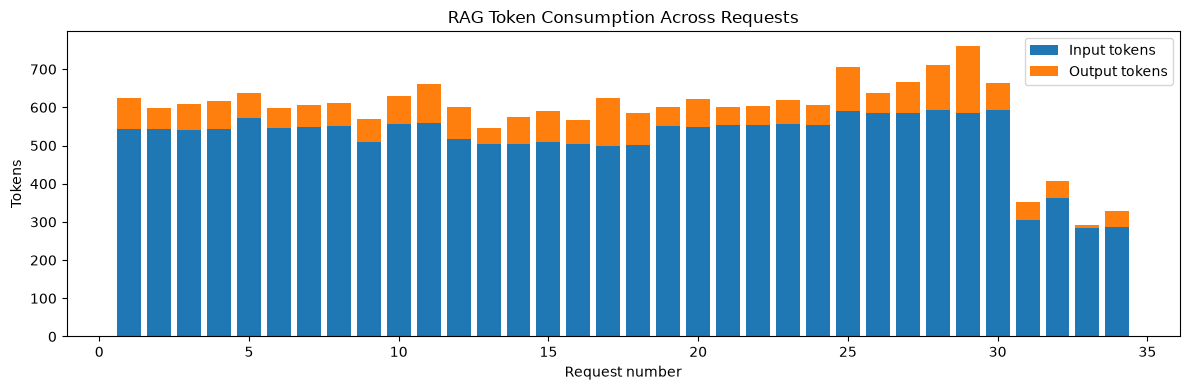

In [24]:
import matplotlib.pyplot as plt

# Inspect one of the 34 collected traces
t = traces[0]

print("Question:", t["question"])
print("Retrieved:", t["hits"])
print("Packed:", t["packed"])
print("Prompt hash:", t["prompt_sha"])
print("Tokens:", t["usage"])

# Visualize token consumption across all traces
inputs = [t["usage"]["input"] for t in traces]
outputs = [t["usage"]["output"] for t in traces]
requests = range(1, len(traces) + 1)

plt.figure(figsize=(12, 4))
plt.bar(requests, inputs, label="Input tokens")
plt.bar(requests, outputs, bottom=inputs, label="Output tokens")

plt.xlabel("Request number")
plt.ylabel("Tokens")
plt.title("RAG Token Consumption Across Requests")
plt.legend()
plt.tight_layout()
plt.show()

__visualize token cost across all 34 requests.__

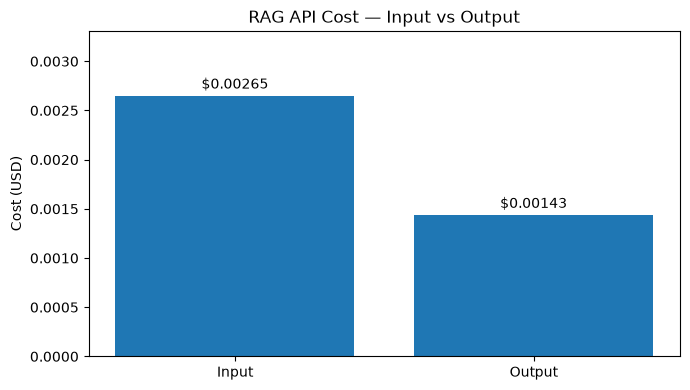

Total estimated cost: $0.00408


In [25]:
# Estimate input vs output costs in USD
# Example pricing: gpt-4o-mini (per 1 million tokens)
INPUT_PRICE = 0.15
OUTPUT_PRICE = 0.60

input_cost = sum(t["usage"]["input"] for t in traces) * INPUT_PRICE / 1_000_000
output_cost = sum(t["usage"]["output"] for t in traces) * OUTPUT_PRICE / 1_000_000

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(["Input", "Output"], [input_cost, output_cost])
ax.bar_label(bars, fmt="$%.5f", padding=3)

ax.set_ylabel("Cost (USD)")
ax.set_title("RAG API Cost — Input vs Output")
ax.set_ylim(0, max(input_cost, output_cost) * 1.25)

plt.tight_layout()
plt.show()

print(f"Total estimated cost: ${input_cost + output_cost:.5f}")

---

## Part C: Screen the answers (self-study)

We have collected 34 traces, but we haven't checked the answers yet. Which ones should we investigate first?

For each question, Part B kept an `expected` list containing reference answer strings. For example, the first question asks which NFL team represented the AFC at Super Bowl 50, and its expected answer is `['Denver Broncos']`.

The model replied: *The Denver Broncos represented the AFC at Super Bowl 50.*

The wording is longer than the reference answer, but it contains the expected phrase. We can use this observation to build a **screen**: a quick check that flags answers for us to read.

### What will the screen check?

Our screen asks: **Does the model's answer contain at least one expected phrase as whole words?**

$$
\text{pass}(a, E) = \text{some } e \in E \text{ appears in } a \text{ as whole words}
$$

- $a$ is the model's answer, converted to lower-case words with `words()` from Lab 02.
- $E$ is the list of expected answer strings for that question.
- **At least one** means that matching any accepted wording is enough to pass.

For example, `words("Denver Broncos!")` becomes `"denver broncos"`. This lets us ignore capitalisation and punctuation when comparing the texts.

__Why check whole words?__

A simple substring check would find `"no"` inside `"know"`. To prevent that, we add a space at both ends of the normalised texts. We then look for `" no "` inside `" know "`, which does not match.

The function below uses Python's [`any()`](https://docs.python.org/3/library/functions.html#any) to return `True` as soon as one expected phrase is found. We will first try it on the real Super Bowl answer, then apply it to all 34 traces.

__Important:__ This is an exact-phrase containment check, rather than the full-answer exact-match metric used in some evaluations. The answer may contain extra words and still pass. We are using it to decide which answers to inspect, so we must also understand what it can miss.


In [21]:
# screen(): True when one expected string appears in the answer as whole words; tried on the first trace
def screen(answer_text, expected):
    answer = f" {words(answer_text)} "
    return any(f" {words(text)} " in answer for text in expected)

first = parse(traces[0]["reply"])["answer"]
print(first, "| expected:", questions[0]["expected"])
print("passes:", screen(first, questions[0]["expected"]))


The Denver Broncos represented the AFC at Super Bowl 50. | expected: ['Denver Broncos']
passes: True


The first answer passes because it contains *Denver Broncos*. Let's follow how we read that answer from the trace:

1. `traces[0]["reply"]` is the raw response string we saved in Part B.
2. `parse(...)` checks the JSON structure and converts it into a Python dictionary.
3. `["answer"]` selects the answer sentence from that dictionary.
4. `screen(...)` compares the sentence with the question's expected phrases.

Now we will repeat this for every trace.

- `answers` will hold the 34 answer sentences.
- `passed` will hold one `True` or `False` per answer, in the same order.
- `zip(answers, questions)` pairs each answer with the question it belongs to.

**Why does the order matter?** We traced the questions in order in Part B. Keeping that order means `answers[0]`, `questions[0]` and `passed[0]` all describe the same request. Comparing an answer with another question's reference would give a meaningless result.

Only the questions were sent to `trace()`. The expected answers are used here, after generation, to check what came back.


In [26]:
# answers: the answer sentence of every trace; passed: one True or False per question, in the same order
answers = [parse(t["reply"])["answer"] for t in traces]
passed = [screen(a, q["expected"]) for a, q in zip(answers, questions)]
print(f"passed {sum(passed)} of {len(passed)}")
for a, q, ok in zip(answers, questions, passed):
    if not ok:
        print(f"\n{q['question']}\n  expected: {q['expected']}\n  answer:   {a}")


passed 31 of 34

What measure of a computational problem broadly defines the inherent difficulty of the solution?
  expected: ['if its solution requires significant resources', 'its solution requires significant resources']
  answer:   Computational complexity theory broadly defines the inherent difficulty of a computational problem.

Can temporary Atlas accounts reset by email?
  expected: ['support agent']
  answer:   Insufficient evidence.

Do I need the mobile app to reset my Atlas password?
  expected: ['no', 'by email']
  answer:   Yes, password reset uses a mobile app.


In the saved screening result above, **31 of 34 answers pass**. The three flagged answers concern computational complexity, temporary Atlas accounts and the mobile app. Your model may answer them differently; read the questions your own run flags.

### What does a pass mean?

A pass means that an expected phrase appears in the answer. It doesn't tell us whether the complete answer is correct or supported by the evidence.

For example, an answer that says *The Denver Broncos lost to the Carolina Panthers* still contains *Denver Broncos*. This screen would pass it, even though the sentence adds an incorrect claim.

A failure also needs inspection. A model might express the correct idea using words that our reference list does not contain. Part E will show this with the complexity question.

We therefore use the screen to create a **review list**. Lab 02's quote checks and Lab 07's calibrated judge examine other aspects of an answer; no single phrase check covers them all.

### Checkpoint C

| You should see | Saved screening result |
|---|---|
| The screen | `passed 31 of 34` |
| Flagged questions | complexity, temporary accounts and mobile app |
| Meaning of `False` | read this answer and compare it with its evidence and reference answers |

We now know which traces to inspect. Next, we will use the information inside each trace to decide where to start looking.


---

## Part D: Find the stage where the support was lost

An answer can be wrong for several reasons. Perhaps the document was never loaded, search missed the right passage, packing left it out, or the model failed to use it correctly. Part D follows the evidence through these stages so that we can choose what to investigate.

If you ran Parts B and C without stopping on their explanations, these are the objects they created:

| Object | What it holds |
|---|---|
| `questions` | 34 questions: 30 SQuAD questions and four Atlas questions, each with `expected` answers and `support` IDs |
| `traces` | One record per question: retrieved hits, packed IDs, raw reply, prompt hash, usage and stamp |
| `answers` | The answer sentence read from each trace's JSON reply |
| `passed` | The screen's `True` or `False` result for each answer |

All four lists use the same question order.

### What do we mean by support?

**Support** is the paragraph or policy labelled as containing the evidence needed to answer the question. For the SQuAD questions, this comes from `known_support`. For the Atlas questions, we supplied the relevant policy IDs in Part B.

For example, H01 is the labelled support for *Can temporary Atlas accounts reset by email?* It contains the rule that temporary accounts require a support agent.

We will use **failure attribution by stage**: check whether that support was present in the corpus, retrieved by search, and included in the evidence sent to the model. The first failed check tells us where to begin investigating.

Start by printing the flagged answers beside their expected phrases and support IDs. `zip(questions, answers, passed)` brings together the three pieces for one question; `if not ok` keeps the questions whose answers failed the screen.


In [27]:
# flagged: the questions whose answer failed the screen, with their support, expected strings and the answer given
flagged = [(q, a) for q, a, ok in zip(questions, answers, passed) if not ok]
for q, a in flagged:
    print(f"{q['question']}\n  support: {q['support']} | expected: {q['expected']}\n  answer:  {a}\n")


What measure of a computational problem broadly defines the inherent difficulty of the solution?
  support: ['S04-P01'] | expected: ['if its solution requires significant resources', 'its solution requires significant resources']
  answer:  Computational complexity theory broadly defines the inherent difficulty of a computational problem.

Can temporary Atlas accounts reset by email?
  support: ['H01'] | expected: ['support agent']
  answer:  Insufficient evidence.

Do I need the mobile app to reset my Atlas password?
  support: ['H01'] | expected: ['no', 'by email']
  answer:  Yes, password reset uses a mobile app.



The saved screening result gives us three cases to investigate:

- **Complexity:** The model names the field, *computational complexity theory*. The reference answers describe what makes a problem difficult: *its solution requires significant resources*.
- **Temporary accounts:** The model says *Insufficient evidence.*, although H01 contains the support-agent rule.
- **Mobile app:** The model says *Yes, password reset uses a mobile app.* That sentence comes from H04, the Boreal policy. The question asks about Atlas, whose support is H01.

These observations describe the answers. To diagnose the pipeline, we also need to check where the supporting evidence went.

| What happened to the labelled support? | Stage to inspect | What we would check next |
|---|---|---|
| Missing from the corpus | corpus | Was the document loaded and its text preserved? |
| In the corpus, missing from the hits | retrieval | Did chunking, question wording or ranking prevent it from being retrieved? |
| In the hits, missing from the pack | packing | Did the token budget, ordering or a filter leave it out? |
| In the pack, but the answer fails the screen | generation | How did the model use the evidence, and is the screen's reference answer adequate? |

Before running the next cell, use the three cases above to predict where we will need to look.

### Compare IDs at the same level

There is one detail we must handle before checking membership:

- The trace stores **chunk IDs**, such as `S04-P01-C00`.
- A SQuAD question's `support` stores **paragraph IDs**, such as `S04-P01`.

These refer to related evidence, but their strings differ. We must map the chunk back to its source paragraph before comparing it with `support`.

`source_of` creates this lookup. For example, `source_of["S04-P01-C00"]` gives `"S04-P01"`. A policy such as H01 maps to itself because we kept each policy as one chunk.

The `stages()` function then returns four checks for one question. For the temporary-accounts answer above, a row with the support present throughout would look like:

```python
{"corpus": True, "hits": True, "pack": True, "answer": False}
```

The first three values track evidence presence. The last value comes from the answer screen; it is not a separate check of whether the model understood the evidence.


In [28]:
# source_of: chunk ID -> paragraph ID; stages(): True or False for each stage one support reached; table: one row per question
source_of = {chunk["chunk_id"]: chunk["source_id"] for chunk in corpus}

def stages(t, q, ok):
    return {"corpus": any(chunk["source_id"] in q["support"] for chunk in corpus),
            "hits": any(source_of[chunk_id] in q["support"] for chunk_id, _ in t["hits"]),
            "pack": any(source_of[chunk_id] in q["support"] for chunk_id in t["packed"]),
            "answer": ok}

table = [stages(t, q, ok) for t, q, ok in zip(traces, questions, passed)]
for step in ("corpus", "hits", "pack"):
    print(f"support in the {step:7} {sum(row[step] for row in table)} of {len(table)}")
print(f"answer passes screen {sum(row['answer'] for row in table)} of {len(table)}")
print(f"\n{settings['CHAT_MODEL']} at {chat_url(settings)}")


support in the corpus  34 of 34
support in the hits    34 of 34
support in the pack    34 of 34
answer passes screen 31 of 34

gpt-4o-mini at https://api.openai.com/v1


### How to read the stage table

1. `stages(t, q, ok)` receives one trace, its question record and its screening result.
2. Each `any(...)` asks whether **at least one** labelled supporting source is present at that stage.
3. `table` collects one row per question.
4. The loop adds the `True` values for each column. In Python, `True` counts as 1 and `False` as 0 when summed.

For this question set, each question has one labelled supporting source. A question that requires evidence from several sources would need a stronger check: finding only one of them might be insufficient.

In the reference run, the labelled support is present in the corpus, hits and pack for **all 34 questions**. The answer screen passes 31. This tells us that the three flagged answers reached generation with their labelled support available.

__Does having the source in the pack prove the model had everything it needed?__

The table checks source IDs. It does not read the text to establish that a particular chunk contains the complete answer, and it does not check whether nearby evidence is distracting. We still need to inspect the packed text.

### Name the first failed check

The next cell uses `next((step for step in row if not row[step]), None)` to find the first `False` value in each row.

The row's keys were created in pipeline order: `corpus`, `hits`, `pack`, `answer`. For the example row above, `next(...)` returns `"answer"`; the `STAGE` dictionary gives it the stage name `"generation"`. If every value is `True`, it returns the default `None`, and the cell prints nothing for that question.

We also print the support's rank and the packed IDs. `enumerate(...)` starts at zero, so `i + 1` turns its index into a rank: 1 means the first hit.


In [29]:
# lost: the first stage whose value is False, None when every stage passed; ranks: the hit positions of the support
# the line also shows the packed IDs, so the pack can be read beside the ranks
STAGE = {"corpus": "corpus", "hits": "retrieval", "pack": "packing", "answer": "generation"}

for t, q, row in zip(traces, questions, table):
    lost = next((step for step in row if not row[step]), None)
    if lost:
        ranks = [i + 1 for i, (chunk_id, _) in enumerate(t["hits"]) if source_of[chunk_id] in q["support"]]
        print(f"{STAGE[lost]:10} | support at hit {ranks} | packed {t['packed']} | {q['question']}")


generation | support at hit [1, 4] | packed ['S04-P01-C00', 'S04-P00-C00', 'S04-P02-C01', 'S04-P01-C01', 'S04-P02-C00'] | What measure of a computational problem broadly defines the inherent difficulty of the solution?
generation | support at hit [1] | packed ['H01', 'H04', 'H02', 'H05', 'H03'] | Can temporary Atlas accounts reset by email?
generation | support at hit [2] | packed ['H04', 'H01', 'H02', 'H05', 'H03'] | Do I need the mobile app to reset my Atlas password?


In the reference run, all three flagged answers are assigned to **generation**. The labelled support was retrieved and packed in each case:

- **Complexity:** Paragraph `S04-P01` appears through two chunks, `S04-P01-C00` and `S04-P01-C01`, at hits 1 and 4.
- **Temporary accounts:** H01 is the first hit and is packed, yet the model refuses to answer.
- **Mobile app:** H01 is the second hit and is packed. H04, the Boreal policy, ranks first.

### What have we learned?

We have narrowed the investigation. Loading the documents again or increasing retrieval depth would not explain these failures: the labelled support already reached the prompt.

However, `generation` is only the first place our checks fail. It doesn't tell us whether the model was distracted by another passage, the rules encouraged a refusal, or the screen rejected a valid wording.

In Part E, we will simplify the evidence to separate these possibilities.

### Checkpoint D

| You should see | Reference run |
|---|---|
| Evidence presence | corpus, hits and pack: 34 of 34 each |
| Answer screen | 31 of 34 |
| First failed check | `generation` for the three flagged answers |
| Support ranks | complexity: 1 and 4; temporary accounts: 1; mobile app: 2 |

If your flagged questions differ, use their rows and packed evidence to make the same investigation. The stage names should follow your results.


---

## Part E: Give the model only the labelled passage (self-study)

Part D showed that the labelled support reached the model. Now we want to know whether the model can answer when we remove the other retrieved passages.

We will use **oracle context**: supply the passage named by the question's support label directly, instead of asking search and packing to choose the evidence. Here, "oracle" means that the evaluation labels tell us which passage to provide.

For the mobile-app question, for example, we will send H01 alone. H04 and the other retrieved chunks will be absent.

### Why do this?

This gives us a simpler diagnostic experiment:

| Result with the labelled passage alone | What it tells us to investigate |
|---|---|
| The answer becomes correct | The model can answer from this support. Inspect the original evidence selection, surrounding passages and ordering. |
| The answer is still wrong or refused | Inspect the answer instructions, the model's use of the passage and the reference answers. |

We are replacing the original pack with full labelled passages, so more than the number of passages may change: their length, IDs and presentation can differ too. This experiment narrows the investigation. The challenge later removes one packed line at a time to test a particular distractor.

__Important:__ Oracle context is for diagnosis. A real user does not supply a support label, so these answers must be kept separate from the pipeline's retrieval-based evaluation results.

First, create a lookup from paragraph or policy ID to its full text. We read the original SQuAD passages because the labels name paragraphs; the chunk file contains only their pieces. Then we select the questions whose answers failed the screen.


In [30]:
# passages: paragraph or policy ID -> its full text; failed: the questions the screen flagged
passages = {p["source_id"]: p["text"] for p in json.loads((DATA / "squad-passages.json").read_text(encoding="utf-8"))}
passages.update({p["source_id"]: p["text"] for p in policies})

failed = [q for q, ok in zip(questions, passed) if not ok]
for q in failed:
    print(q["support"], "|", passages[q["support"][0]][:110], "...")


['S04-P01'] | A problem is regarded as inherently difficult if its solution requires significant resources, whatever the alg ...
['H01'] | Atlas passwords can be reset by email. Temporary accounts require a support agent. ...
['H01'] | Atlas passwords can be reset by email. Temporary accounts require a support agent. ...


The preview shows the support ID and the start of its passage for each flagged question. `passages.update(...)` added the policy texts to the same lookup, so we can read a SQuAD paragraph or an Atlas policy by its source ID.

Next, we will format each question's support as the same `[ID] text` evidence lines used earlier. We will pass those lines directly to `answer()` from Lab 02.

- `answer()` uses the same default `RULES` and response schema as our trace call.
- It parses and validates the reply, with one retry if needed. We read the returned dictionary's `"answer"` field.
- We call it **five times per question**, because model responses can vary even when the question and evidence stay the same.

We will report two things: how many answers pass our phrase screen, and what the model actually says. Read both. A screen failure may be a valid paraphrase.

[`Counter`](https://docs.python.org/3/library/collections.html#collections.Counter) groups identical answer strings and counts them. `.most_common()` prints the most frequent wording first; two differently worded answers are counted separately even if they mean the same thing.


In [31]:
# oracle: the support passage as the only evidence line; oracle_answers: five answers from it, counted by wording
from collections import Counter
from shared.answer import answer

for q in failed:
    oracle = [f"[{source_id}] {passages[source_id]}" for source_id in q["support"]]
    oracle_answers = [answer(q["question"], oracle, settings)["answer"] for _ in range(5)]
    print(f"\n{q['question']} | passes the screen {sum(screen(a, q['expected']) for a in oracle_answers)} of 5")
    for text, n in Counter(oracle_answers).most_common():
        print(f"  {n} of 5 | {text}")



What measure of a computational problem broadly defines the inherent difficulty of the solution? | passes the screen 0 of 5
  4 of 5 | The measure of a computational problem that broadly defines the inherent difficulty of the solution is the amount of resources needed to solve them, such as time and storage.
  1 of 5 | The measure of a computational problem that broadly defines the inherent difficulty of the solution is the quantification of the amount of resources needed to solve them, such as time and storage.

Can temporary Atlas accounts reset by email? | passes the screen 0 of 5
  5 of 5 | Insufficient evidence.

Do I need the mobile app to reset my Atlas password? | passes the screen 5 of 5
  5 of 5 | No, you do not need the mobile app to reset your Atlas password.


### Compare the answer with its evidence

For each question, `oracle` contains only its labelled passages. The list comprehension calls `answer()` five times, and `screen(...)` compares each returned sentence with the reference phrases.

The reference run gave three different patterns.

**1. Mobile app: the answer becomes correct.**

With H01 alone, the model answered *No, you do not need the mobile app to reset your Atlas password.* in 5 of 5 calls. The phrase screen passed all five.

The model can answer this question from H01. In the original pack, H04 ranked first and contained *Password reset uses a mobile app.* H04 describes Boreal, but that sentence does not name the product. This makes it a likely distractor. Task 1 tests that explanation by removing individual lines from the original pack.

**2. Complexity: the answer improves, but the screen still fails.**

The model answered *the amount of resources needed to solve them, such as time and storage* in 5 of 5 calls. The supporting passage describes difficulty by quantifying resources, so this expresses the right idea.

Why did the screen return `False`? Its expected phrases include *its solution requires significant resources*. None of those complete phrases appears in the new answer.

The reference list is **incomplete**: it records the wording people marked in SQuAD, rather than every valid way to answer. In the original pack, the model named the field; with the labelled passage alone, it gives an acceptable answer that our screen cannot recognise. We need to inspect both the evidence and the evaluation rule.

**3. Temporary accounts: the model still refuses.**

The model answered *Insufficient evidence.* in 5 of 5 calls, even with H01 alone. Removing the other passages did not resolve the refusal.

H01 says temporary accounts require a support agent. To answer the question, the model needs to connect that rule to whether email reset is available.

### Test the abstention instruction

Our rules tell the model to say *Insufficient evidence.* when the evidence does not answer the question. Could that instruction be making it too cautious here?

We will remove only that sentence, keep H01 as the evidence, and ask the same temporary-accounts question five more times. `rules_without != RULES` checks that the replacement actually changed the rules.

This is a diagnostic comparison. Before adopting a changed instruction, we would also need to rerun questions where refusal is the correct behaviour.


In [32]:
# rules_without: the rules with the abstention line removed; oracle_answers: five answers from H01 alone under them
ABSTAIN = ' If the evidence does not answer the question, the answer is "Insufficient evidence." and the claims list is empty.'
rules_without = RULES.replace(ABSTAIN, "")
temporary = next(q for q in questions if "temporary" in q["question"])

print("abstention line removed:", rules_without != RULES)
oracle_answers = [answer(temporary["question"], [f"[H01] {passages['H01']}"], settings, rules=rules_without)["answer"]
                  for _ in range(5)]
for text, n in Counter(oracle_answers).most_common():
    print(f"  {n} of 5 | {text}")


abstention line removed: True
  5 of 5 | Temporary Atlas accounts cannot reset by email; they require a support agent.


Without the abstention sentence, the reference run answered in 5 of 5 calls that temporary accounts cannot reset by email and require a support agent.

We now have evidence that this instruction contributes to the refusal **for this question, model and passage**. Removing it changed the behaviour while the supporting evidence stayed the same.

__Should we remove the abstention rule from the application?__

This experiment alone does not justify that change. The rule also helps the model refuse questions the documents cannot answer. We could revise it to allow conclusions directly supported by the evidence, then evaluate both answerable and unanswerable questions. Fixing this one refusal while introducing unsupported answers elsewhere would be a poor repair.

### Put the diagnoses together

| Question | Original stage check | Oracle-context result in the reference run | What to investigate next |
|---|---|---|---|
| Mobile app | `generation` | Correct with H01 alone, 5 of 5 | Inspect the other packed lines, especially H04. Test leaving it out; product metadata filtering is one possible repair (Lab 11). |
| Complexity | `generation` | Correct idea in different words, 5 of 5; screen passes 0 of 5 | Review accepted answers or use a calibrated judge (Lab 07). Also inspect why the original pack pulled the model toward the field's name. |
| Temporary accounts | `generation` | Refused with H01 alone, 5 of 5; answered without the abstention sentence, 5 of 5 | Revise and test the instruction, including cases that should still be refused. |


The stage table placed all three cases at generation, but the follow-up experiments point to different changes: evidence selection, the answer reference, and the instruction.

We can now explain why we would make each change and which question we would rerun to check it. We should also rerun the wider question set to look for regressions: answers that used to work but become worse after a change.

### Checkpoint E

| You should see | Reference run |
|---|---|
| Mobile app, oracle | Correct *No, you do not need the mobile app ...* in 5 of 5; screen passes all five |
| Complexity, oracle | Correct resources explanation in other words, 5 of 5; screen passes 0 of 5 |
| Temporary accounts, oracle | Refused in 5 of 5; answered in 5 of 5 after removing the abstention sentence |

Your counts and wording can vary. Compare the actual answers with the passage before deciding what the experiment shows. If there are no flagged answers in your run, the oracle loop has no questions to process; that does not demonstrate that the pipeline will handle every future question.


---

## Part F: Save the baseline in `shared/trace.py` (self-study)

We have collected traces, screened answers and investigated failures. When we change the pipeline in a later lab, how will we know whether the change helped?

We need a **baseline**: a saved set of results from the pipeline we are comparing against. Later, we can run the same questions through a changed pipeline and compare the results question by question.

A baseline can contain wrong answers. Its purpose is to record the starting behaviour, including the failures we want to improve.

### Keep the tracing code in one place

`shared/trace.py` keeps the steps we have already built:

| Function | What it does |
|---|---|
| `corpus()` | Loads the 272 SQuAD chunks and five policies as 277 searchable records |
| `trace(...)` | Searches, packs evidence, makes one answer call and returns the trace record |
| `baseline(settings)` | Traces the 30 development questions and saves them, or reads a matching saved file |

The baseline uses the **30 development questions**, rather than all 34 questions in Part B. The four Atlas cases were added here to investigate policy failures; they are not included in this baseline file.

The file is saved in `.cache/`. Its name includes the chat model and a hash built from configuration metadata, rules and question texts. This keeps, for example, two models or endpoints from sharing a baseline file accidentally. Inspect the code below to see what goes into that key.

We use `inspect.getsource(shared.trace)` to print the module's code. These helpers let later labs reuse the pipeline without copying all its cells.


In [33]:
# shared.trace: the module; inspect.getsource() prints its code as written
import inspect
import shared.trace

print(inspect.getsource(shared.trace))


"""Trace records for the pipeline: the steps Lab 04 builds by hand, kept for the labs after it.

trace() runs one question through search, packing and the answer call, and returns what each step produced:
the hits, the packed IDs, a hash of the prompt, the raw reply, the tokens billed and the stamp. baseline() traces
the 30 development questions once and saves them in .cache/, in a file named after the chat model and a hash of
the settings, the rules and the questions, so a changed model or endpoint never reuses old traces.
"""
from __future__ import annotations

import hashlib
import json

from shared.answer import RULES, pack, response_format
from shared.search import chunk_vectors, search
from shared.settings import DATA, ROOT, chat_client, chat_options, stamp


def corpus() -> list[dict]:
    """The 272 chunks plus the five policies, each policy as one chunk whose ID is its source ID."""
    chunks = json.loads((DATA / "squad-chunks.json").read_text(encoding="utf-8"))
    policies 

### Run once, then read the saved records

The next cell calls `baseline(settings)` twice:

1. If no matching file exists, the first call traces all 30 questions and writes the results to `.cache/`.
2. The second call reads those saved records. It does not ask the model again.
3. `baseline(settings) == base` checks that the records read back are equal to the ones returned by the first call.

If you have already run a lab that created this baseline, both calls may read the cache.

We will also compare the baseline's prompt hashes with the first 30 traces from Part B. Those traces belong to the same 30 development questions, in the same order.

Remember Part B's distinction: **matching prompt hashes identify matching message texts**. They do not prove that the entire API request or the model's response was identical.

Finally, we apply our screen to the baseline answers. This describes the saved starting behaviour; it is not a target that a baseline must pass.


In [34]:
# base: the 30 baseline traces, traced on the first call and read from .cache/ on the second
from shared.trace import baseline

base = baseline(settings)
print(len(base), "traces | read back the same:", baseline(settings) == base)
print("baseline files:", sorted(path.name for path in (ROOT / ".cache").glob("baseline-*.json")))
print("same prompts as Part B:", sum(b["prompt_sha"] == t["prompt_sha"] for b, t in zip(base, traces)), "of", len(base))
print("passed the screen:", sum(screen(parse(b["reply"])["answer"], q["expected"]) for b, q in zip(base, questions)),
      "of", len(base))
print(f"\n{settings['CHAT_MODEL']} at {chat_url(settings)}")


30 traces | read back the same: True
baseline files: ['baseline-gpt-4o-mini-c358e23dfda2.json']
same prompts as Part B: 30 of 30
passed the screen: 29 of 30

gpt-4o-mini at https://api.openai.com/v1


The reference baseline contains **30 traces**, and the second call reads back the same records. All 30 prompt hashes match their corresponding Part B traces. The screen passes 29 of 30 baseline answers; the complexity answer is the one it flags.

### What does this comparison tell us?

- **Read back the same: `True`** means the cache preserved the trace records. It does not show that a fresh model call would repeat those answers.
- **Same prompts: 30 of 30** means the message texts match. If the model and other request settings also stay the same, different replies can still arise from model variability.
- **Passed the screen: 29 of 30** describes this saved baseline under our simple phrase check. It does not establish that every passing answer is correct.

The reference filename is `baseline-gpt-4o-mini-<hash>.json`. Your filename follows the model and settings you use. Later labs call `baseline()` and `trace()` by name, using the pipeline we have now examined.

__When should we refresh a baseline?__

Keep the saved baseline when you want to compare a candidate against the original results. For a new starting point, deliberately regenerate it. The cache key includes the fields shown in the module; it does not automatically detect every possible change, such as edits to corpus files or tracing code.

### Checkpoint F

| You should see | Reference run |
|---|---|
| Saved baseline | 30 traces; `read back the same: True` |
| Prompt comparison | 30 of 30 match Part B |
| Answer screen | 29 of 30 pass |
| Cache | A `baseline-<model>-<hash>.json` file in `.cache/` |


---

## What you can do now

- Build a trace by hand and explain what the hits, packed IDs, prompt hash, raw reply, usage and stamp record.
- Trace a question set with one function and total the token usage from its records.
- Screen answers against expected phrases, keeping the results separate from a judgement of correctness.
- Follow a labelled source through the corpus, retrieval and packing to choose where to investigate a flagged answer.
- Use oracle context to test the model with the labelled passage alone, and recognise when a reference list misses a valid answer.
- Save and reload a baseline so that later pipeline changes can be compared with the same starting results.


## Challenge

Use the tracing and diagnosis steps from this lab. Task 1 tests a suspected distracting passage. Task 2 is optional practice for failures that happened earlier in the pipeline.

For each task, keep the printed results and your answer to **Explain**.

1. **Find the line that misled the model.** The oracle experiment showed that H01 alone could answer the mobile-app question. Now keep the original evidence pack and remove just one line at a time.

   Complete `without_each()` under Task 1. For each packed line, leave it out, call `answer()` three times with the remaining lines, and collect the omitted ID with a `Counter` of the answer strings. The cell tries this on the mobile-app and complexity questions.

   **Check:** In the reference runs, removing H04 gave the correct *No, you do not need the mobile app ...* in 3 of 3 calls; removing other lines kept a *Yes*. For complexity, results varied: sometimes no single removal fixed it; sometimes removing `S04-P00-C00`, about classifying problems by inherent difficulty, moved the reply toward resources (3 of 3 in one run, 1 of 3 in another).

   **Explain:** Which removal changed the answer in your run? What repair does it suggest? Why can a true statement about Boreal mislead an answer about Atlas?

2. **Optional: name the first failed stage.** The reference run's 34 questions all had their labelled support retrieved and packed. To practise other failures, Task 2 supplies three deliberately written traces for *How long does an Atlas reset link remain valid?*

   Complete `stage_of()` by screening the answer, calling `stages()` and mapping its first failed check through `STAGE`.

   **Check:** `['retrieval', 'packing', 'generation']`

   **Explain:** Where does H02 stop in each trace? What would you change first, and which question would you rerun to test that change?


### Task 1: Remove one evidence line at a time

`without_each()` already retrieves and packs the evidence. Complete the loop after that step:

- Start each trial from the **original full pack**, then make `shorter` by excluding one line. Do not keep removing lines from an already shortened pack.
- Ask the same question three times with `answer(question, shorter, settings)` and keep each returned `"answer"` string.
- Extract the omitted line's ID with `line[1:line.index("]")]` and pair it with a `Counter` of those three answers.
- Return the list of these pairs so the provided printing loop can display them.

We keep the question, instructions and remaining lines the same. This lets us examine how the answer changes when one piece of evidence is absent. Read different wordings for meaning as well as counting them.


In [ ]:
# without_each(): for each packed line, the three answers given when that line is left out of the evidence
def without_each(question):
    """For each packed line: its ID, and three answers to the question from the other lines."""
    lines = pack(search(question, corpus, vectors, settings, k=5), settings)
    # TODO: for each line, answer the question three times from the other lines (answer(question, shorter, settings));
    #       collect (the left-out line's ID, line[1:line.index("]")], with Counter(...) of the three answers)
    return None

for q in [q for q in questions if "mobile app" in q["question"] or "measure" in q["question"]]:
    result = without_each(q["question"])
    if result is None:
        print("⚠️ Complete without_each, then run the cell again.")
        break
    print(q["question"])
    for left_out, counts in result:
        print(f"  without {left_out:12} {counts.most_common()}")

### Task 2: Trace where H02 stops (optional)

The three traces below are constructed examples, rather than model runs. Each has the wrong answer *Atlas reset links last 24 hours.* H02 is the supporting policy, and its expected answer is *30 minutes*.

Read each trace's `hits` and `packed` fields before completing `stage_of()`:

1. Parse `t["reply"]` and screen its answer against `q["expected"]` to obtain `ok`.
2. Pass `t`, `q` and `ok` to `stages()`.
3. Find the first check whose value is `False`, then return its stage name using `STAGE`.

Use the order from Part D: corpus, hits, pack, answer. All three answers are wrong, but the first place the support is missing differs.


In [ ]:
# written: three hand-written traces for the Atlas question; stage_of(): the first stage one of them lost the support
atlas = {"question": "How long does an Atlas reset link remain valid?", "expected": ["30 minutes"], "support": ["H02"]}
written = [  # written by hand, not from a run
    {"hits": [["H01", 0.61], ["H04", 0.55], ["H03", 0.40]], "packed": ["H01", "H04"],
     "reply": '{"answer": "Atlas reset links last 24 hours.", "claims": []}'},
    {"hits": [["H01", 0.61], ["H02", 0.58], ["H04", 0.55]], "packed": ["H01"],
     "reply": '{"answer": "Atlas reset links last 24 hours.", "claims": []}'},
    {"hits": [["H02", 0.70], ["H01", 0.61], ["H04", 0.55]], "packed": ["H02", "H01"],
     "reply": '{"answer": "Atlas reset links last 24 hours.", "claims": []}'},
]

def stage_of(t, q):
    # TODO: screen the answer in t["reply"], build the row with stages(t, q, ok),
    #       and return STAGE[...] of the first step that is False
    return None

found = [stage_of(t, atlas) for t in written]
print(found if None not in found else "⚠️ Complete stage_of, then run the cell again.")

## Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| The stage table says `support in the hits 4 of 34` | chunk IDs compared with paragraph IDs directly; only the policies match, because a policy's chunk ID is its source ID | Map each chunk ID through `source_of` first, as `stages()` does |
| `KeyError: 'S04-P01-C00'` in Part E | a chunk ID looked up in `passages`, which is keyed by paragraph ID | Use the question's `support` list, or `source_of[chunk_id]` |
| `JSONDecodeError: Expecting value: line 1 column 1 (char 0)` from `parse(t["reply"])` | the reply in that trace is not JSON (a server that ignored `response_format`); the trace keeps the reply as it came | Read the raw `reply` in the record; `answer()` asks once more, `trace()` does not. Try `JSON_MODE=json_object` |

## Resources

- [OpenAI: create chat completion](https://developers.openai.com/api/reference/resources/chat/subresources/completions/methods/create):
  `usage`, the token counts a trace records
- [Python: `hashlib`](https://docs.python.org/3/library/hashlib.html): SHA-256 and `hexdigest()`
- [OpenTelemetry: traces](https://opentelemetry.io/docs/concepts/signals/traces/): how tracing tools record each step
  of a request as a span, the production form of these records
- [Joren et al., *Sufficient Context*, ICLR 2025](https://arxiv.org/abs/2411.06037): separating "the context was not
  enough" from "the model failed with enough context"

Next: [Lab 05](../05_Rebuild_With_LangChain/README.md), *How to rebuild a RAG pipeline with LangChain*. Back to [the lab list](../README.md).